This project builds a recurrent model to classify comments into six moderation categories:
- toxic
- severe toxic
- obscene
- threat 
- insult
- identity hate

The project present first a preprocessing of the comments and tokenization of the text, then it predicts a binary label for each category.
An LSTM model is trained and evaluated with metrics suited to multi-label classification, while accounting for class imbalance.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3' 
import tensorflow as tf
tf.compat.v1.logging.set_verbosity(tf.compat.v1.logging.ERROR)

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score, precision_recall_curve
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.layers import TextVectorization, Dense, Embedding, Dropout, Input, LSTM, GRU

from keras.backend import clear_session

import pickle




In [84]:
# BASE_URL = "https://s3.eu-west-3.amazonaws.com/profession.ai/datasets/"
# df = pd.read_csv(BASE_URL+"Filter_Toxic_Comments_dataset.csv")
df=pd.read_csv("Filter_Toxic_Comments_dataset.csv")
df.head()


,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,sum_injurious
0,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0,0
1,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0,0
2,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0,0
3,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0,0
4,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0,0


In [85]:
print("Dataset dimension:", df["comment_text"].count())

Dataset dimension: 159571


In [86]:
df["comment_text"][0]

"Explanation\nWhy the edits made under my username Hardcore Metallica Fan were reverted? They weren't vandalisms, just closure on some GAs after I voted at New York Dolls FAC. And please don't remove the template from the talk page since I'm retired now.89.205.38.27"

In [87]:
classes = ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]

print("Not asssigned comments:\n",df[classes].isna().sum())

statistics=pd.DataFrame()
statistics["tot_occurrences"]=df[classes+ ["sum_injurious"]].sum()
statistics["perc_occurrences"]=(df[classes+ ["sum_injurious"]].sum()/df.shape[0])*100

print("\nOccurrence of different labels:\n", statistics)

Not asssigned comments:
 toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64

Occurrence of different labels:
                tot_occurrences  perc_occurrences
toxic                    15294          9.584448
severe_toxic              1595          0.999555
obscene                   8449          5.294822
threat                     478          0.299553
insult                    7877          4.936361
identity_hate             1405          0.880486
sum_injurious            35098         21.995225


We observe that the dataset is highly unbalanced with some classes (severe_toxic, threat and identity_hate highly underrepresented) 

Next we also observe high level of co-occurrence of different classes, e.g. more than 90% of comments that are severe toxic are also toxic and obscene. 

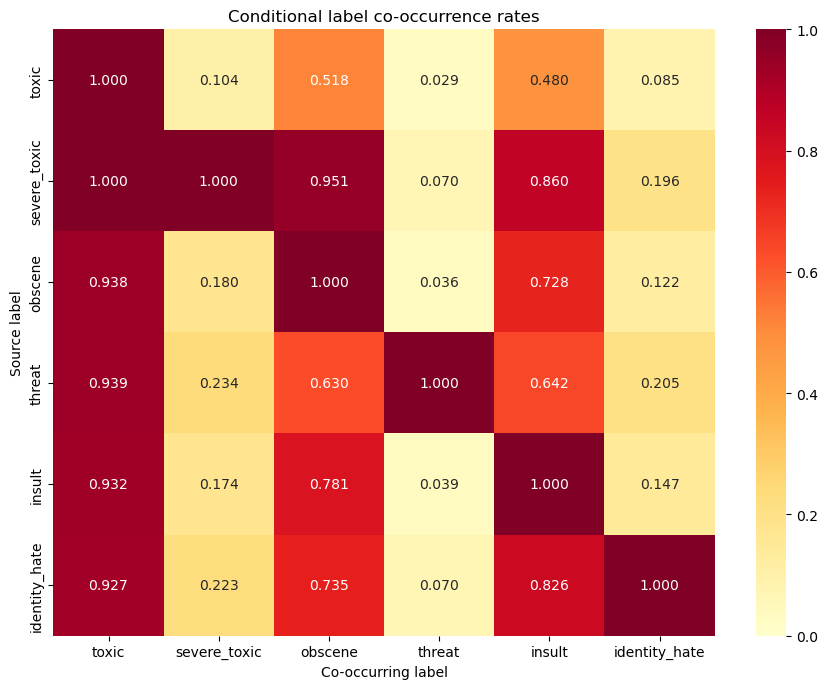

In [88]:
labels = [
    "toxic", "severe_toxic", "obscene",
    "threat", "insult", "identity_hate"
]

y=df[["toxic","severe_toxic","obscene","threat","insult","identity_hate"]].to_numpy()

# Each row is a source label; each column is a co-occurring label.
rates = np.full((len(labels), len(labels)), np.nan)

for source_idx in range(len(labels)):
    in_source = y[:, source_idx] == 1

    # Avoid computing a rate if there are no examples of this source label.
    if in_source.any():
        rates[source_idx, :] = y[in_source].mean(axis=0)

plt.figure(figsize=(9, 7))
sns.heatmap(
    rates,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    vmin=0,
    vmax=1,
    xticklabels=labels,
    yticklabels=labels,
    mask=np.isnan(rates)
)

plt.xlabel("Co-occurring label")
plt.ylabel("Source label")
plt.title("Conditional label co-occurrence rates")
plt.tight_layout()
plt.show()

In [89]:
df[classes+ ["sum_injurious"]].apply(lambda col: col.unique())


toxic                           [0, 1]
severe_toxic                    [0, 1]
obscene                         [0, 1]
threat                          [0, 1]
insult                          [0, 1]
identity_hate                   [0, 1]
sum_injurious    [0, 4, 1, 3, 2, 5, 6]
dtype: object

In [90]:
df[df["sum_injurious"]==6].head(3)

,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate,sum_injurious
1017,WOULDN'T BE THE FIRST TIME BITCH. FUCK YOU I'L...,1,1,1,1,1,1,6
1312,"SHUT UP, YOU FAT POOP, OR I WILL KICK YOUR ASS!!!",1,1,1,1,1,1,6
7299,"You're a stupid cunt \n\nFuck you dumb arse, y...",1,1,1,1,1,1,6


## TRAIN-VAL-TEST SPLITTING

In [91]:
X = df["comment_text"].values.to_numpy()
y = df[["toxic","severe_toxic","obscene","threat","insult","identity_hate"]].to_numpy()

In [92]:
# We split test, validation and training set stratifying on every single class separately
msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.3,
    random_state=1
)

train_idx, test_idx = next(msss.split(X, y))

X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

msss_2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.5,
    random_state=1
)

val_idx, test_idx = next(msss_2.split(X_test, y_test))

X_val = X[val_idx]
X_test = X[test_idx]
y_val = y[val_idx]
y_test = y[test_idx]

y_val = tf.convert_to_tensor(y_val)
y_train = tf.convert_to_tensor(y_train)
y_test = tf.convert_to_tensor(y_test)




## TOKENIZER

We tokenize the comments using a dictionary of 5000 words after standardizing the text in lowercase letters and removing puntuation and special characters, each comments is saved as a sequence of max 150 tokens which correspond the length of 90% of the comments.  

In [93]:
df["text_length"] = df["comment_text"].str.split().str.len()

In [94]:
df["text_length"].describe()

count    159571.000000
mean         67.273527
std          99.230702
min           1.000000
25%          17.000000
50%          36.000000
75%          75.000000
max        1411.000000
Name: text_length, dtype: float64

In [95]:
df["text_length"].quantile(0.9)

np.float64(152.0)

In [96]:
# define the function used to format the test before tokenizing it, it converts a string in lowercase 
# letters, leaves only letters and numbers and removes multple spaces

def clean_text(text):
    text = tf.strings.lower(text)
    text = tf.strings.regex_replace(text, r"[^a-z0-9\s]", "")
    text = tf.strings.regex_replace(text, r"\s+", " ")
    text = tf.strings.regex_replace(text, r"^\s+|\s+$", "")
    return text

In [97]:
num_words = 10000 #words in dictionary
max_len = 150 #with such lenght only 10% of the comments are cutted 
tokenizer = TextVectorization(max_tokens=num_words, output_sequence_length=max_len, output_mode='int', standardize=clean_text, split="whitespace")


In [98]:
tokenizer.adapt(X_train)

In [99]:
train_sequences= tokenizer(X_train)
test_sequences= tokenizer(X_test)
val_sequences=tokenizer(X_val)

In [100]:
print(tokenizer.get_vocabulary()[-10:])
vocabulary_size = len(tokenizer.get_vocabulary())
print("Vocab_size", vocabulary_size)

[np.str_('calculus'), np.str_('cage'), np.str_('butler'), np.str_('brush'), np.str_('browsers'), np.str_('britney'), np.str_('breathing'), np.str_('bobby'), np.str_('birthplace'), np.str_('behaviors')]
Vocab_size 10000


Next, since the different classes are unbalanced,  we create a pipeline that produces batches of training data where classes have different probability to appear. In particular higher probability is given to the classes that are less represented. A perfectly balanced dataset is not possible because of the high level of co-occurance of some classes. 

In [101]:
# 1st We split the training data according to the different classes and save them in a dictionary
class_data=dict()

for i,label  in enumerate(classes):
    indices=(y_train[:,i]==1)
    class_data[label]={
        "features": tf.boolean_mask(train_sequences, indices),
        "labels": tf.boolean_mask(y_train, indices)
    }

# elements not belonging to any toxic class
neg_indices = tf.reduce_all(tf.equal(y_train, 0), axis=1)
class_data["ok"]={"features": tf.boolean_mask(train_sequences, neg_indices),
    "labels": tf.boolean_mask(y_train, neg_indices)}


In [102]:
# Here we create separate training datasets (one for each class) containing only data associated to that class 
# + 1 containing data not associated to any class
BUFFER_SIZE = 50000

def make_ds(features, labels):
# Create a dataset of (feature, label) pairs from the provided data.
  ds = tf.data.Dataset.from_tensor_slices((features, labels))#.cache()
  ds = ds.shuffle(BUFFER_SIZE).repeat()
  return ds

train_ds=dict()

# save a separate dataset for each class in a dictionary
for label in classes+["ok"]:
    train_ds[label] = make_ds(class_data[label]["features"], class_data[label]["labels"])


In [103]:
# EXAMPLE: what is in train_ds
for features, label in train_ds[classes[2]].take(1):
  print("Features:\n", features.numpy())
  print()
  print("Label: ", label.numpy())

Features:
 [6267 4300    7 6403   36   54  166   36  684   36   11 2842  243   54
   42    2  695  210    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0]

Label:  [1 0 1 0 1 0]


In [104]:
n_classes = len(train_ds)-1 
BATCH_SIZE=32

# Create a data set where classes are sampled with different probabilities, these are chosen to balance the magnitude of the occurrence of the different classes.
resampled_ds = tf.data.Dataset.sample_from_datasets([train_ds[label] for label in classes+["ok"]], weights=[.2/(.75*n_classes),.7/(.75*n_classes),.35/(.75*n_classes),.7/(.75*n_classes),.35/(.75*n_classes),.7/(.75*n_classes), .3])
#resampled_ds = tf.data.Dataset.sample_from_datasets([train_ds[label] for label in classes+["ok"]], weights=[.1,.1,.1,.1,.1,.1, .4])


# Create batches from the psuedo-balanced dataset
resampled_ds = resampled_ds.batch(BATCH_SIZE).prefetch(2)

In [105]:
# An epoch is considerd as the number of batches required to see each example in each class at least once:
N_ok_comments=sum(df["sum_injurious"]==0)

p_negative = len(classes) / n_classes
resampled_steps_per_epoch = int(np.ceil(N_ok_comments / (BATCH_SIZE * p_negative)))

In [106]:
val_ds = tf.data.Dataset.from_tensor_slices((val_sequences, y_val)).cache()
val_ds = val_ds.batch(BATCH_SIZE).prefetch(2)

Next we investigate the occurrance of the different classes of the training dataset, psuedo-balanced training batches and validation batches that we have created with the custom choice of the sampling probability from the different classes.

In [107]:
# Distribution of classes in the starting training dataset
prev_train = np.mean(y_train, axis=0)

# Distribution of classes in the starting training dataset
y_val = np.concatenate(
    [y.numpy() for _, y in val_ds],
    axis=0
)
prev_val = np.mean(y_val, axis=0)

# Distribution of classes in a sample of 10000 examples from the oversampled training dataset
y_resampled = next(iter(resampled_ds.unbatch().take(10_000).batch(10_000)))[1].numpy()
prev_resampled = np.mean(y_resampled, axis=0)

for i in range(6):
    print(
        f"Percentage of elements in {classes[i]}: training={prev_train[i]:.3f}, "
        f"oversampled≈{prev_resampled[i]:.3f}, "
        f"validation={prev_val[i]:.3f}"
    )

Percentage of elements in toxic: training=0.096, oversampled≈0.664, validation=0.100
Percentage of elements in severe_toxic: training=0.010, oversampled≈0.273, validation=0.010
Percentage of elements in obscene: training=0.053, oversampled≈0.545, validation=0.054
Percentage of elements in threat: training=0.003, oversampled≈0.198, validation=0.003
Percentage of elements in insult: training=0.049, oversampled≈0.545, validation=0.051
Percentage of elements in identity_hate: training=0.009, oversampled≈0.246, validation=0.009


## MODEL TRAINING

First we define a function to plot the training history. It will be important to balance between precision and recall in the different classes, for this reason during the training we decide to monitor the integral of the Precision-Recall curve.

In [108]:
def plot_history(history, title):
    """plot loss and Precision-Recall curve integral"""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    epochs = range(1, len(history.history['loss']) + 1)

    ax1.plot(epochs, history.history['loss'], label='Train')
    ax1.plot(epochs, history.history['val_loss'],   label='Val')
    ax1.set_title('Loss'); ax1.set_xlabel('Epoch'); ax1.legend()

    ax2.plot(epochs, history.history['prc'], label='Train')
    ax2.plot(epochs, history.history['val_prc'],   label='Val')
    ax2.set_title(' Precision-Recall Curve Integral'); ax2.set_xlabel('Epoch'); ax2.legend()

    fig.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

Next we define our model, an LSTM model with one input layer with 32-units that embedds the differen tokens, one LSTM layes with 64 units and a final dense output that gives the probability for all the classes.

In [109]:
embedding_dim=32
hidden_dim=64

clear_session()

model_LSTM = Sequential()
model_LSTM.add(Input(shape=(max_len,)))
model_LSTM.add(Embedding(vocabulary_size, embedding_dim, mask_zero=True, input_length=max_len))
model_LSTM.add(Dropout(0.1))
model_LSTM.add(LSTM(hidden_dim,activation='tanh'))
model_LSTM.add(Dropout(0.1))
model_LSTM.add(Dense(6,activation='sigmoid'))
model_LSTM.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 150, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 345,222 (1.32 MB)

 Trainable params: 345,222 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [110]:
loss=tf.keras.losses.BinaryCrossentropy(
    from_logits=False,
    label_smoothing=0.0,
    axis=-1,
    reduction="sum_over_batch_size",
    name="binary_crossentropy",
    dtype=None,
)


In [111]:
EPOCHS=30

prc = tf.keras.metrics.AUC(
    curve="PR",
    multi_label=True,
    num_labels=6,
    name="prc"
)

def early_stopping():
 return tf.keras.callbacks.EarlyStopping(
    monitor='val_prc',
    verbose=1,
    patience=3,
    mode='max',
    restore_best_weights=True)

model_LSTM.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.), loss=loss, metrics=[prc])


history_LSTM=model_LSTM.fit(resampled_ds,
                            epochs=EPOCHS, 
                            steps_per_epoch=resampled_steps_per_epoch,
                            callbacks=[early_stopping()],
                            validation_data=val_ds)

with open("lstm_model.pkl", "wb") as f:
    pickle.dump(model_LSTM, f)

Epoch 1/30
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 279s 62ms/step - loss: 0.1999 - prc: 0.9383 - val_loss: 0.0684 - val_prc: 0.7229
Epoch 2/30
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 412s 92ms/step - loss: 0.0962 - prc: 0.9857 - val_loss: 0.0619 - val_prc: 0.7690
Epoch 3/30
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 365s 81ms/step - loss: 0.0687 - prc: 0.9924 - val_loss: 0.0583 - val_prc: 0.7907
Epoch 4/30
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 313s 70ms/step - loss: 0.0534 - prc: 0.9955 - val_loss: 0.0512 - val_prc: 0.7957
Epoch 5/30
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 229s 51ms/step - loss: 0.0443 - prc: 0.9968 - val_loss: 0.0473 - val_prc: 0.8271
Epoch 6/30
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 240s 54ms/step - loss: 0.0378 - prc: 0.9976 - val_loss: 0.0491 - val_prc: 0.8240
Epoch 7/30
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 237s 53ms/step - loss: 0.0330 - prc: 0.9980 - val_loss: 0.0447 - val_prc: 0.8306
Epoch 8/30
4480/4480 ━━━━━━━━━━━━━━━━━━━━ 225s 50ms/step - loss: 0.0288 - prc: 0.9984 - val_loss: 0.0444 - val_prc: 0.8300
Epoch 9/30
4480/

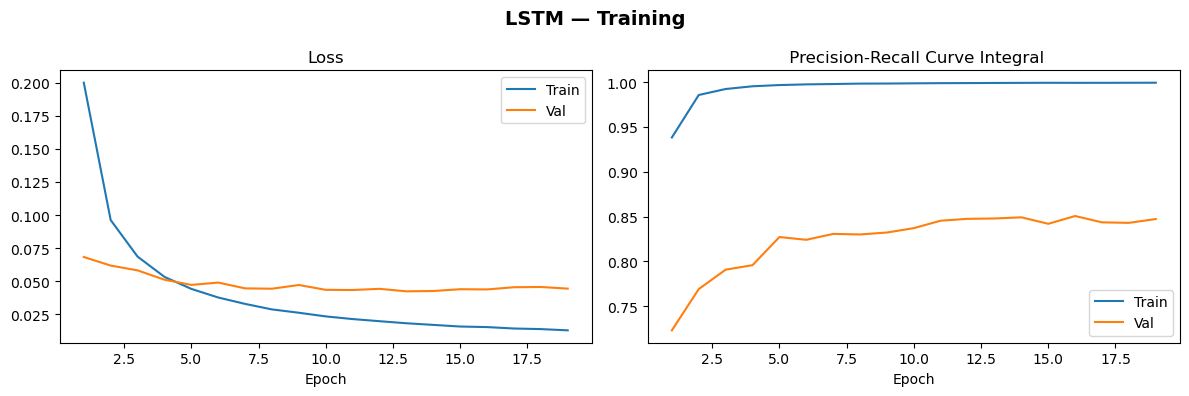

In [112]:
plot_history(history_LSTM, 'LSTM — Training')

The trained model has a very high value of the precision-recall curve integral on the training set which could show some overfitting. Nontheless, reducing the number of parameters reduced significantly the performances also on the validation set. For this reason we accept this model even it could be partially overfitted. We also point out that in the training set and the validation one, by construction, the diffent classes are differently represented so a direct comparison of the metrics on the two datasets may be misleading.  

In [113]:
prediction_prob = model_LSTM.predict(test_sequences)

748/748 ━━━━━━━━━━━━━━━━━━━━ 13s 17ms/step


Next we visualize the performance of the model on the different classes of comments.

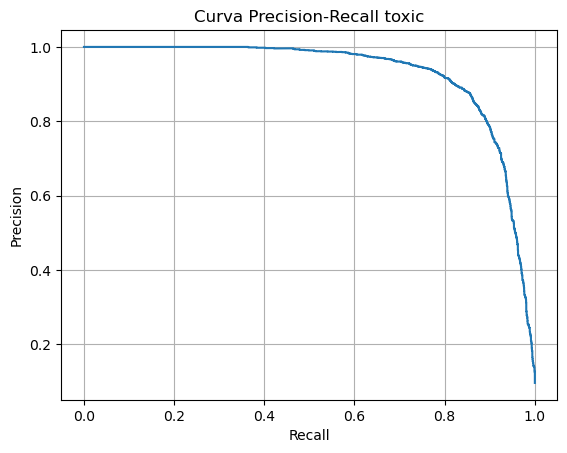


 - toxic : threshold 0.5 

              precision    recall  f1-score   support

           0       0.98      0.99      0.99     21628
           1       0.88      0.85      0.87      2308

    accuracy                           0.97     23936
   macro avg       0.93      0.92      0.93     23936
weighted avg       0.97      0.97      0.97     23936

Confusion matrix:
[[21350   278]
 [  335  1973]]


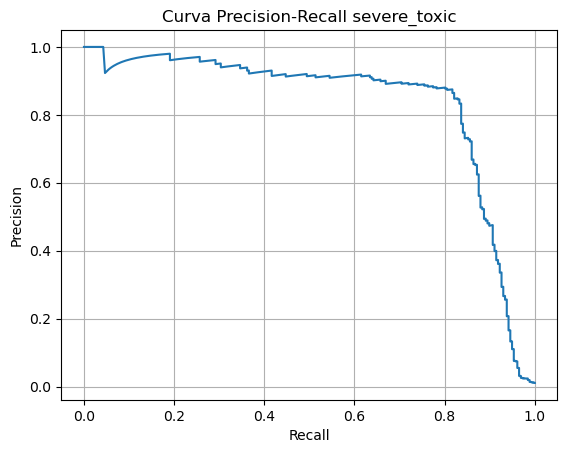


 - severe_toxic : threshold 0.8 

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     23679
           1       0.86      0.82      0.84       257

    accuracy                           1.00     23936
   macro avg       0.93      0.91      0.92     23936
weighted avg       1.00      1.00      1.00     23936

Confusion matrix:
[[23645    34]
 [   46   211]]


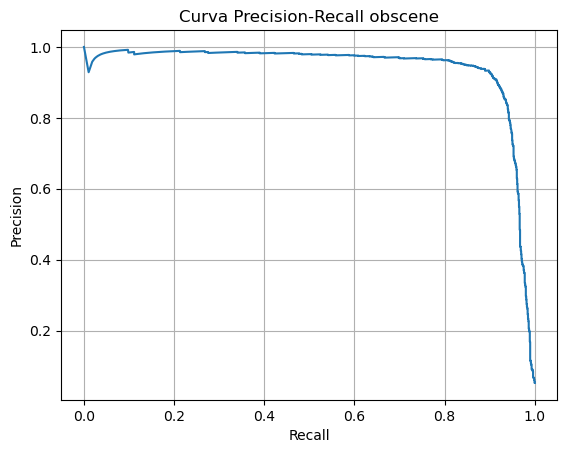


 - obscene : threshold 0.9 

              precision    recall  f1-score   support

           0       0.99      1.00      1.00     22687
           1       0.94      0.89      0.91      1249

    accuracy                           0.99     23936
   macro avg       0.97      0.94      0.95     23936
weighted avg       0.99      0.99      0.99     23936

Confusion matrix:
[[22612    75]
 [  138  1111]]


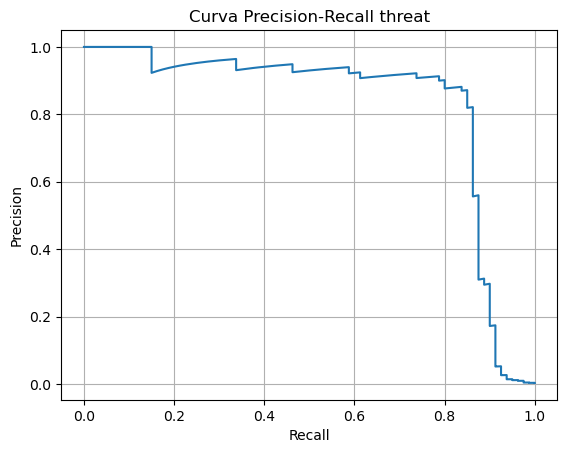


 - threat : threshold 0.9 

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     23856
           1       0.87      0.85      0.86        80

    accuracy                           1.00     23936
   macro avg       0.94      0.92      0.93     23936
weighted avg       1.00      1.00      1.00     23936

Confusion matrix:
[[23846    10]
 [   12    68]]


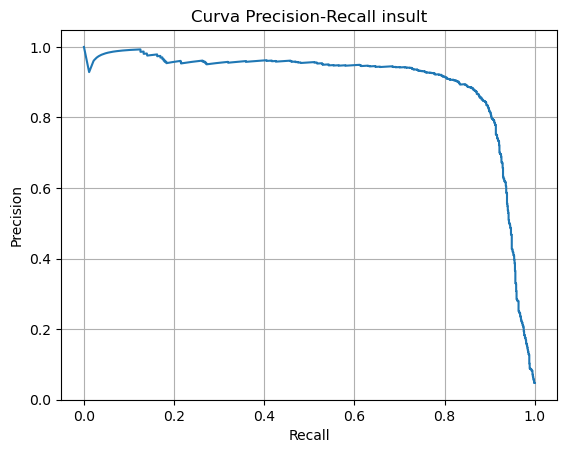


 - insult : threshold 0.8 

              precision    recall  f1-score   support

           0       0.99      0.99      0.99     22803
           1       0.88      0.86      0.87      1133

    accuracy                           0.99     23936
   macro avg       0.94      0.93      0.93     23936
weighted avg       0.99      0.99      0.99     23936

Confusion matrix:
[[22669   134]
 [  153   980]]


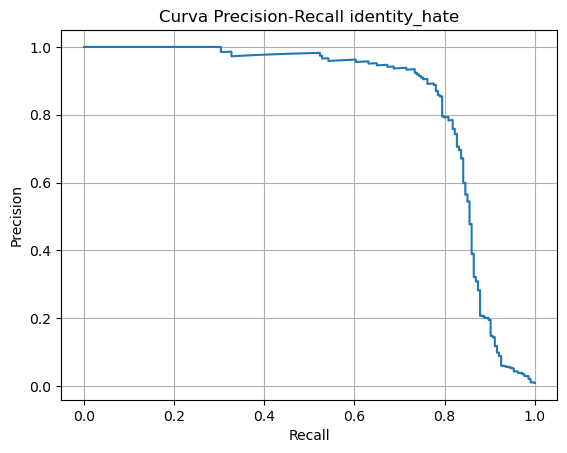


 - identity_hate : threshold 0.9 

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     23722
           1       0.84      0.79      0.82       214

    accuracy                           1.00     23936
   macro avg       0.92      0.90      0.91     23936
weighted avg       1.00      1.00      1.00     23936

Confusion matrix:
[[23690    32]
 [   44   170]]


In [119]:
threshold=[0]*6
prediction=prediction_prob.copy()

for i,label in enumerate(classes):
    T=.2
    best_F1=0
    precision, recall, thresholds = precision_recall_curve(y_test[:,i], prediction_prob[:,i])
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Curva Precision-Recall {label}")
    plt.grid(True)
    plt.show()

    for j in range(8):
        prediction[:,i]=(prediction_prob[:,i] > T).astype(int)
        F1 = f1_score(y_test[:,i], prediction[:,i])
        if F1>best_F1:
            best_F1=F1
            threshold[i]=T
        T=T+0.1

    prediction[:,i]=(prediction_prob[:,i] > threshold[i]).astype(int)
    print(f"\n - {label} : threshold {threshold[i]:.1f} \n")
    print(classification_report(y_test[:,i], prediction[:,i]))
    print("Confusion matrix:")
    print(confusion_matrix(y_test[:,i],prediction[:,i]))
    


The trained model has an F1 score higher thatn 0.8 on all the three classes that we consider acceptable. We note that many classes present very few examples and on these classes, despite the oversampling, the predictions are not as good as on the other classes.